# Определение сделки на Авито

## 1. Загрузка данных

### 1.1. Пути и настройки

Запустите ноутбук из корня проекта через **Run All**. Сделкой считаем продажу покупателю, который связался с продавцом через Авито.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

DATA = Path("data")
CHAT_FEATURES_PATH = Path("feature/chat_features.csv")
CHAT_LABELS_PATH = Path("feature/good_examples_of_verified_by_messages.csv")
OUTPUT_PATH = Path("submission.csv")

CHAT_MODEL_SHARE = 0.75
CHAT_LABEL_WEIGHT = 0.10
CHAT_C = 0.3
VERIFIED_C = 1.0

CV_SEEDS = [11, 23, 42, 71, 101, 13, 29, 59, 83, 107]
THRESHOLDS = np.round(np.arange(0.20, 0.71, 0.01), 2)
INNER_SEED = 42

### 1.2. Исходные таблицы

In [2]:
listings_raw = pd.read_csv(DATA / "listings.csv")
events_raw = pd.read_csv(DATA / "events.csv")
messages_raw = pd.read_csv(DATA / "messages.csv")
surveys_raw = pd.read_csv(DATA / "surveys.csv")
verified = pd.read_csv(DATA / "verified.csv")

source_tables = {
    "listings": listings_raw,
    "events": events_raw,
    "messages": messages_raw,
    "surveys": surveys_raw,
    "verified": verified,
}
display(pd.DataFrame({
    "Строк": {name: len(table) for name, table in source_tables.items()},
    "Уникальных ID": {
        name: table["listing_id"].nunique() for name, table in source_tables.items()
    },
}))

,Строк,Уникальных ID
listings,15457,15274
events,183242,14789
messages,352209,13805
surveys,6061,5942
verified,300,300


### 1.3. Ключи и проверенные ответы

In [3]:
listing_ids = pd.Index(listings_raw["listing_id"].drop_duplicates(), name="listing_id")
assert listing_ids.notna().all(), "В карточках есть пустые ID"
assert verified["listing_id"].is_unique, "В verified повторяются ID"
assert verified["listing_id"].isin(listing_ids).all(), "Для проверенных ID нет карточек"
assert verified["is_deal"].isin([0, 1]).all(), "Некорректная метка сделки"

display(verified["is_deal"].value_counts().rename("Объявлений"))

is_deal
0    184
1    116
Name: Объявлений, dtype: int64

## 2. Анализ данных и поиск признаков

### 2.1. Дубли, пропуски и аномалии

Сначала считаем проблемы в исходных таблицах. Для проверки цены и дат берём по одной карточке на объявление. Правила из этого раздела применим в блоке очистки.

In [4]:
quality = pd.DataFrame({
    "Точных дублей": {name: table.duplicated().sum() for name, table in source_tables.items()},
    "Строк с пропусками": {
        name: table.isna().any(axis=1).sum() for name, table in source_tables.items()
    },
    "Строк без карточки": {
        name: (~table["listing_id"].isin(listing_ids)).sum() for name, table in source_tables.items()
    },
})
display(quality)

listings = listings_raw.drop_duplicates().copy()
assert listings["listing_id"].is_unique, "У одного ID несколько разных карточек"

date_columns = ["published_at", "closed_at"]
parsed_dates = listings[date_columns].apply(pd.to_datetime, errors="coerce")
bad_time = parsed_dates.isna().any(axis=1) | parsed_dates["published_at"].ge(parsed_dates["closed_at"])
price_columns = ["price", "current_price"]
high_prices = listings[price_columns].gt(20_000_000).any(axis=1)
low_prices = listings[price_columns].lt(20).any(axis=1)
bad_prices = high_prices | low_prices

display(pd.Series({
    "Противоречивые или пропущенные даты": bad_time.sum(),
    "Цена выше 20 млн": high_prices.sum(),
    "Цена ниже 20": low_prices.sum(),
    "Цена или даты требуют очистки": (bad_prices | bad_time).sum(),
    "Пропущена категория": listings["category"].isna().sum(),
}, name="Объявлений"))

,Точных дублей,Строк с пропусками,Строк без карточки
listings,183,839,0
events,1814,183242,0
messages,0,1409,0
surveys,119,0,0
verified,0,0,0


Противоречивые или пропущенные даты     40
Цена выше 20 млн                        98
Цена ниже 20                            85
Цена или даты требуют очистки          223
Пропущена категория                    381
Name: Объявлений, dtype: int64

### 2.2. Распределения и корреляции

Смотрим, какие счётчики меняются вместе. Пары с модулем корреляции от 0,8 показываем один раз. Это помогает заметить признаки с похожей информацией.

,count,mean,std,min,25%,50%,75%,max
price,15091.0,7703.314558,8379.213690,120.0,2290.0,4900.0,9960.00,105640.0
current_price,15091.0,7479.169041,8149.489526,120.0,2220.0,4760.0,9640.00,105640.0
photos_count,15274.0,4.239034,2.178421,0.0,3.0,4.0,6.00,10.0
description_length,14816.0,141.522881,126.762915,9.0,65.0,105.0,174.00,1997.0
views_total,15274.0,137.177622,148.304019,0.0,37.0,83.0,189.75,1624.0
favorites_total,15274.0,4.488870,5.059177,0.0,1.0,3.0,6.00,49.0
phone_views_total,15274.0,1.388307,1.918389,0.0,0.0,1.0,2.00,20.0
chats_total,15274.0,5.805421,6.625386,0.0,2.0,3.0,8.00,70.0
messages_total,15274.0,23.059382,24.971809,0.0,6.0,16.0,31.00,300.0


price        current_price      0.997411
views_total  favorites_total    0.934678
             chats_total        0.898121
             messages_total     0.824053
chats_total  messages_total     0.923677
Name: Корреляция Спирмена, dtype: float64

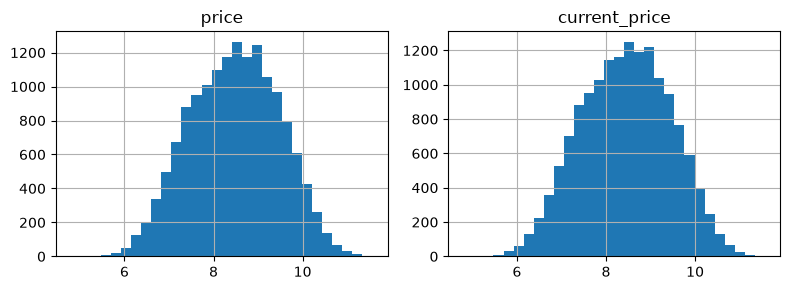

In [5]:
measures = [
    "price", "current_price", "photos_count", "description_length",
    "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total",
]
card_values = listings[measures].copy()
card_values.loc[bad_prices, price_columns] = np.nan
display(card_values.describe().T)

correlations = card_values.corr(method="spearman")
upper_triangle = np.triu(np.ones(correlations.shape, dtype=bool), k=1)
strongest_pairs = correlations.where(upper_triangle).stack()
display(strongest_pairs.loc[strongest_pairs.abs().ge(0.8)].rename("Корреляция Спирмена"))

card_values[price_columns].apply(np.log1p).hist(bins=30, figsize=(8, 3))
plt.tight_layout()
plt.show()

### 2.3. Цена, срок жизни и активность объявления

Сравниваем карточки со сделкой и без неё. Для цены берём медиану категории, чтобы учитывать разницу в ценах между категориями. Число сообщений делим на число чатов, чтобы увидеть, как много общались с одним покупателем.

In [6]:
card_research = listings[["listing_id", "category", *measures]].copy()
card_research.loc[bad_prices, price_columns] = np.nan
category_median = card_research.groupby("category")["price"].transform("median")
card_research["price_to_category_median"] = card_research["price"] / category_median
card_research["discount_pct"] = (
    (card_research["price"] - card_research["current_price"]) / card_research["price"]
)
card_research["lifetime_days"] = (
    (parsed_dates["closed_at"] - parsed_dates["published_at"]).dt.total_seconds() / 86_400
).mask(bad_time)
card_research["messages_per_chat"] = (
    card_research["messages_total"] / card_research["chats_total"].replace(0, np.nan)
)
card_research = verified.merge(card_research, on="listing_id", validate="one_to_one")

checked_columns = [
    "price_to_category_median", "discount_pct", "lifetime_days",
    "views_total", "phone_views_total", "chats_total", "messages_per_chat",
]
display(card_research.groupby("is_deal")[checked_columns].agg(["count", "median"]).T.round(2))
lifetime_groups = pd.cut(card_research["lifetime_days"], [0, 1, 7, 29, np.inf])
display(card_research.groupby(lifetime_groups, observed=True)["is_deal"].agg(
    listings="size", deals="sum", deal_share="mean"
).round(3))

is_deal                               0       1
price_to_category_median count   176.00  112.00
                         median    1.14    0.90
discount_pct             count   180.00  115.00
                         median    0.00    0.00
lifetime_days            count   184.00  115.00
                         median   11.93    8.41
views_total              count   184.00  116.00
                         median   83.50   75.50
phone_views_total        count   184.00  116.00
                         median    1.00    1.00
chats_total              count   184.00  116.00
                         median    4.00    3.00
messages_per_chat        count   164.00  112.00
                         median    3.40    5.00

,listings,deals,deal_share
lifetime_days,,,
"(0.0, 1.0]",5,1,0.200
"(1.0, 7.0]",109,50,0.459
"(7.0, 29.0]",79,37,0.468
"(29.0, inf]",106,27,0.255


В блоке 4 сравниваем цену с похожими товарами по нормализованному заголовку и категории. Скидку, длительность и число сообщений на чат считаем отдельно.

### 2.4. Ответы продавцов

Сопоставляем ответы опроса с `verified`. В таблице видно, сколько раз каждый ответ совпал с проверенной сделкой.

In [7]:
survey_answers = surveys_raw[["listing_id", "answer"]].drop_duplicates()
assert survey_answers["listing_id"].is_unique, "У объявления несколько ответов опроса"
checked_signals = verified.merge(
    survey_answers, on="listing_id", how="left", validate="one_to_one"
)
checked_signals["answer"] = checked_signals["answer"].fillna("Без ответа")
display(checked_signals.groupby("answer")["is_deal"].agg(
    listings="size", deals="sum", deal_share="mean"
).round(3))

checked_cards = verified.merge(
    listings[["listing_id", "close_type"]], on="listing_id", how="left", validate="one_to_one"
)
display(checked_cards.groupby("close_type")["is_deal"].agg(
    listings="size", deals="sum", deal_share="mean"
).round(3))

,listings,deals,deal_share
answer,,,
Без ответа,185,62,0.335
Другая причина,16,6,0.375
Передумал продавать,17,1,0.059
Продал в другом месте,29,5,0.172
Продал на Авито,53,42,0.792


,listings,deals,deal_share
close_type,,,
заблокировано,2,0,0.000
истёк срок,106,27,0.255
снято продавцом,192,89,0.464


В блоке 4 добавляем отдельные флаги для каждого варианта ответа и для объявлений без ответа.

### 2.5. Чат и показ телефона

Группируем события по объявлению и покупателю, чтобы проверить, воспользовался ли один человек обоими способами связи. Показ телефона означает, что покупатель открыл номер.

In [8]:
contacts_research = events_raw.loc[
    events_raw["event_type"].isin(["chat_start", "phone_view"]),
    ["listing_id", "user_id", "event_type"],
].drop_duplicates()
contacts_research["has_chat"] = contacts_research["event_type"].eq("chat_start")
contacts_research["has_phone"] = contacts_research["event_type"].eq("phone_view")
contact_columns = ["has_chat", "has_phone"]
channels = contacts_research.groupby("listing_id")[contact_columns].any()
buyer_channels = contacts_research.groupby(["listing_id", "user_id"])[contact_columns].any()
same_buyer = buyer_channels.all(axis=1).groupby("listing_id").any()

checked_contacts = verified.join(channels, on="listing_id", validate="one_to_one")
checked_contacts[contact_columns] = checked_contacts[contact_columns].eq(True)
checked_contacts["same_buyer"] = checked_contacts["listing_id"].isin(same_buyer.index[same_buyer])
display(checked_contacts.groupby(contact_columns)["is_deal"].agg(
    listings="size", deals="sum", deal_share="mean"
).round(3))
both_channels = checked_contacts[contact_columns].all(axis=1)
display(checked_contacts.loc[both_channels].groupby("same_buyer")["is_deal"].agg(
    listings="size", deals="sum", deal_share="mean"
).round(3))

listings  deals  deal_share
has_chat has_phone                             
False    False            16      0       0.000
         True              8      4       0.500
True     False           109     47       0.431
         True            167     65       0.389

,listings,deals,deal_share
same_buyer,,,
False,159,57,0.358
True,8,8,1.000


В блоке 4 считаем число уникальных покупателей и число тех, кто открыл телефон и начал чат. Для модели берём события после проверки времени.

### 2.6. Этапы переписки

Проверяем, чем отличаются запрос адреса, выезд и благодарность после выезда. Порядок реплик сравниваем внутри одного чата. Для проверки отдельной гипотезы ищем ответ о продаже в другом чате того же объявления.

In [9]:
message_research = messages_raw.loc[
    messages_raw["listing_id"].isin(verified["listing_id"])
].copy()
message_research["sent_at"] = pd.to_datetime(message_research["sent_at"], errors="coerce")
words = (message_research["text"].fillna("").str.casefold().str.replace("ё", "е")
         .str.replace(r"[^а-яa-z]+", " ", regex=True).str.strip())
buyer = message_research["author"].eq("buyer")
seller = message_research["author"].eq("seller")
chat_keys = ["listing_id", "chat_id"]
message_research["address_request"] = buyer & words.str.contains(
    r"^куда подъехать|^скиньте адрес|^когда можно подъехать"
)
masks = {
    "departure": buyer & words.str.contains(r"^(?:еду|выезжаю|подъехал|я на месте|уже подхожу)\b"),
    "thanks": buyer & words.isin(["все супер спасибо", "спасибо все отлично"]),
    "refusal": buyer & words.str.contains(
        r"купил в другом месте|не приеду|не смогу приехать|передумал|не возьму|не подошло"
    ),
    "unavailable": seller & words.isin(
        ["продано", "уже продано", "извините уже продал", "уже нет извините"]
    ),
}
latest = pd.DataFrame({
    name: message_research.loc[mask].groupby(chat_keys)["sent_at"].max()
    for name, mask in masks.items()
})

In [10]:
chat_signals = pd.DataFrame(index=latest.index)
chat_signals["departed"] = latest["departure"].notna()
chat_signals["refusal_after_departure"] = latest["refusal"].gt(latest["departure"])
chat_signals["thanks_after_departure"] = (
    latest["thanks"].gt(latest["departure"]) & ~chat_signals["refusal_after_departure"]
)
chat_signals["seller_reports_unavailable"] = latest["unavailable"].notna()

open_chat = chat_signals["departed"] & ~(
    chat_signals["thanks_after_departure"] | chat_signals["refusal_after_departure"]
)
departures = latest.loc[open_chat, ["departure"]].reset_index()
reported_sales = latest[["unavailable"]].dropna().reset_index()
chat_pairs = departures.merge(
    reported_sales, on="listing_id", suffixes=("_arrival", "_sale")
)
other_chat = chat_pairs["chat_id_arrival"].ne(chat_pairs["chat_id_sale"])
later_sale = chat_pairs["unavailable"].gt(chat_pairs["departure"])

listing_signals = chat_signals.groupby("listing_id").any()
requested_address = message_research.groupby("listing_id")["address_request"].any()
listing_signals = listing_signals.join(requested_address, how="outer", validate="one_to_one")
listing_signals["unavailable_after_departure_other_chat"] = listing_signals.index.isin(
    chat_pairs.loc[other_chat & later_sale, "listing_id"]
)

checked_chats = listing_signals.reindex(verified["listing_id"]).eq(True)
checked_chats["is_deal"] = verified.set_index("listing_id")["is_deal"]
signal_rows = checked_chats.melt(id_vars="is_deal", var_name="signal", value_name="observed")
display(signal_rows.groupby(["signal", "observed"])["is_deal"].agg(
    listings="size", deals="sum", deal_share="mean"
).round(3))

listings  deals  deal_share
signal                                 observed                             
address_request                        False          187     45       0.241
                                       True           113     71       0.628
departed                               False          234     57       0.244
                                       True            66     59       0.894
refusal_after_departure                False          298    116       0.389
                                       True             2      0       0.000
seller_reports_unavailable             False          262     96       0.366
                                       True            38     20       0.526
thanks_after_departure                 False          289    105       0.363
                                       True            11     11       1.000
unavailable_after_departure_other_chat False          291    107       0.368
                                       True             9      9       1.000

Один сигнал может встречаться в нескольких чатах. В таблице считаем каждое объявление один раз. Здесь используем короткий набор фраз на исходных сообщениях. В блоке 4 применяем полный набор масок к очищенным сообщениям и проверяем итоговые признаки.

### 2.7. От анализа к расчётам

| Наблюдение | Что делаем дальше |
|---|---|
| Цены выходят за допустимый диапазон, даты противоречат друг другу. | В блоке 3 заменяем сомнительные значения пропусками и сверяем состав объявлений. |
| Стоимость зависит от товара, а объём переписки — от числа чатов. | В блоке 4 считаем относительную цену, срок размещения и число сообщений на чат. |
| Ответы продавца и события покупателя дают разные сведения об исходе. | Добавляем флаги опросов, число покупателей и контакты по двум каналам. |
| Исход зависит от того, что произошло после выезда и в каком чате. | Переиспользуем последовательности в признаках благодарности, отказа и сообщения о продаже в другом чате. |

Разбор опирается на расчёты из `analysis/data_clearing.ipynb`, `analysis/analyzing_of_verified.ipynb` и `feature/feature_engineering.ipynb`. Доли в этом разделе описывают проверенную выборку. Качество модели считаем по отложенным прогнозам в блоке 6.

## 3. Очистка данных

### 3.1. Цены и даты в карточках

In [11]:
listings[date_columns] = parsed_dates
listings.loc[bad_time, date_columns] = pd.NaT
listings.loc[bad_prices, price_columns] = np.nan

assert listings.loc[bad_time, date_columns].isna().all().all()
assert listings.loc[bad_prices, price_columns].isna().all().all()
assert set(listings["listing_id"]) == set(listing_ids), "Потеряны объявления после очистки"
display(listings[date_columns + price_columns].isna().sum().rename("Пропусков после очистки"))

published_at      40
closed_at         40
price            183
current_price    183
Name: Пропусков после очистки, dtype: int64

### 3.2. События, сообщения и опросы

При известных датах карточки оставляем события и сообщения за время её жизни. При пропущенных датах сохраняем записи с корректным временем, чтобы использовать остальные признаки.

In [12]:
def clean_timed_rows(table, time_column):
    unique_rows = table.drop_duplicates().copy()
    unique_rows[time_column] = pd.to_datetime(unique_rows[time_column], errors="coerce")
    checked = unique_rows.merge(
        listings[["listing_id", *date_columns]], on="listing_id", how="inner",
        validate="many_to_one",
    )
    dates_missing = checked[date_columns].isna().any(axis=1)
    within_dates = checked[time_column].between(checked["published_at"], checked["closed_at"])
    valid_time = checked[time_column].notna() & (dates_missing | within_dates)
    return checked.loc[valid_time, unique_rows.columns].copy()

events = clean_timed_rows(events_raw, "event_time")
messages = clean_timed_rows(messages_raw, "sent_at")
surveys = surveys_raw.loc[surveys_raw["listing_id"].isin(listing_ids)].drop_duplicates().copy()
assert surveys["listing_id"].is_unique, "После очистки у объявления несколько опросов"
display(pd.DataFrame({
    "До очистки": [len(listings_raw), len(events_raw), len(messages_raw), len(surveys_raw)],
    "После очистки": [len(listings), len(events), len(messages), len(surveys)],
}, index=["Объявления", "События", "Сообщения", "Опросы"]))

,До очистки,После очистки
Объявления,15457,15274
События,183242,181400
Сообщения,352209,351762
Опросы,6061,5942


### 3.3. Пропущенные категории

Восстанавливаем категорию, если у карточек с тем же заголовком она одна. Категория нужна в том числе для расчёта ошибки долей сделок.

In [13]:
title_categories = listings.dropna(subset=["category"]).groupby("title")["category"]
unambiguous_titles = title_categories.nunique().eq(1)
title_to_category = title_categories.first().loc[unambiguous_titles]
missing_category = listings["category"].isna()
listings.loc[missing_category, "category"] = listings.loc[missing_category, "title"].map(title_to_category)
print("Восстановлено категорий", missing_category.sum() - listings["category"].isna().sum())
print("Карточек с неизвестной категорией", listings["category"].isna().sum())

Восстановлено категорий 381
Карточек с неизвестной категорией 0


## 4. Расчёт признаков

### 4.1. Карточки объявлений

In [14]:
def safe_divide(numerator, denominator):
    return numerator / denominator.replace(0, np.nan)

In [15]:
features = listings.copy()

features["region"] = (
    features["region"]
    .str.strip()
    .str.lower()
    .str.replace(r"^г\.\s*", "", regex=True)
)

region_map = {
    "moscow": "москва",
    "масква" : "москва",
    "мск" : "москва",
    "спб": "санкт-петербург",
    "санкт-питербург" : "санкт-петербург",
    "msk" : "москва",
    "питер": "санкт-петербург",
    "санкт петербург": "санкт-петербург",
    "екб": "екатеринбург",
    "новосиб" : "новосибирск",
    "н. новгород": "нижний новгород"
}

features["region"] = features["region"].replace(region_map)

print(features["region"].value_counts())

region
москва             4541
санкт-петербург    3061
краснодар          1431
екатеринбург       1348
новосибирск        1332
казань             1320
нижний новгород    1158
самара             1083
Name: count, dtype: int64


In [16]:
features["description_missing"] = features["description_length"].isna().astype(int)

In [17]:
title = features["title"].str.lower().str.strip()

features["is_used"] = title.str.endswith(" б/у").astype(int)
features["is_new"] = (
    title.str.endswith(" новый")
    & ~title.str.endswith(" как новый")
).astype(int)

features["is_like_new"] = title.str.endswith(" как новый").astype(int)
features["has_documents"] = title.str.endswith(" с документами").astype(int)
features["is_negotiable"] = title.str.endswith(" торг").astype(int)
features["is_urgent"] = title.str.endswith(" срочно").astype(int)
features["is_excellent"] = title.str.endswith(" отличное состояние").astype(int)
features["has_package"] = title.str.contains(
    r"\b(?:коробка|коробкой|упаковка|упаковкой)\b",
    case=False,
    na=False
).astype(int)

suffix_pattern = (
    r"\s+(?:в хорошем состоянии|отличное состояние|"
    r"с документами|как новый|б/у|новый|торг|срочно)$"
)

features["base_title"] = title.str.replace(
    suffix_pattern, "", regex=True
)

features["is_good_condition"] = (
    title.str.endswith(" в хорошем состоянии").astype(int)
)

print("Товарных групп:", features["base_title"].nunique())
print(features["base_title"].value_counts().describe())

print("До:", features["title"].nunique())
print("После:", features["base_title"].nunique())

display(features["base_title"].value_counts().head(20))

# относительная цена

features["product_median_price"] = (
    features.groupby("base_title")["price"].transform("median")
)

features["relative_price"] = (
    features["price"] / features["product_median_price"]
)

features["relative_current_price"] = (
    features["current_price"] / features["product_median_price"]
)

features["log_relative_price"] = np.log(
    features["relative_price"]
)

display(
    features[
        [
            "title",
            "base_title",
            "category",
            "price",
            "product_median_price",
            "relative_price"
        ]
    ].head(15)
)

print(features["relative_price"].describe())

print(
    features["base_title"].value_counts().describe()
)

Товарных групп: 80
count     80.000000
mean     190.925000
std       52.265092
min      111.000000
25%      147.750000
50%      176.000000
75%      235.250000
max      309.000000
Name: count, dtype: float64
До: 720
После: 80


base_title
худи оверсайз             309
рюкзак городской          300
кроссовки nike            300
платье вечернее           291
костюм мужской            279
сапоги зимние             275
джинсы levi's             274
видеокарта gtx 1660       267
пальто шерстяное          266
пуховик женский           261
iphone 12 128 гб          258
наушники беспроводные     257
свитер вязаный            256
колонка jbl               256
ботинки кожаные           252
планшет huawei matepad    252
электронная книга         248
фотоаппарат canon         247
игровая приставка         245
ноутбук lenovo ideapad    239
Name: count, dtype: int64

,title,base_title,category,price,product_median_price,relative_price
0,Пуховик женский б/у,пуховик женский,Одежда и обувь,570.0,1530.0,0.372549
1,Рюкзак городской с документами,рюкзак городской,Одежда и обувь,NaN,1615.0,NaN
2,Комод,комод,Мебель и интерьер,2080.0,6510.0,0.319508
3,Пуховик женский б/у,пуховик женский,Одежда и обувь,1320.0,1530.0,0.862745
4,Спальный мешок,спальный мешок,Спорт и отдых,5030.0,5690.0,0.884007
5,Смартфон Samsung Galaxy A52 как новый,смартфон samsung galaxy a52,Электроника,15880.0,14665.0,1.082850
6,Кроссовки Nike,кроссовки nike,Одежда и обувь,NaN,1510.0,NaN
7,Самокат взрослый как новый,самокат взрослый,Спорт и отдых,5700.0,4885.0,1.166837
8,Наушники беспроводные с документами,наушники беспроводные,Электроника,7510.0,14680.0,0.511580
9,Тормозные колодки б/у,тормозные колодки,Запчасти и аксессуары,3500.0,4015.0,0.871731


count    15091.000000
mean         1.199346
std          0.793227
min          0.068966
25%          0.666667
50%          1.000000
75%          1.495726
max         10.065359
Name: relative_price, dtype: float64
count     80.000000
mean     190.925000
std       52.265092
min      111.000000
25%      147.750000
50%      176.000000
75%      235.250000
max      309.000000
Name: count, dtype: float64


In [18]:
# Относительная величина снижения цены
features["discount_pct"] = (
    (features["price"] - features["current_price"])
    / features["price"]
)

# Снижалась ли цена к моменту закрытия
features["has_discount"] = (
    (features["current_price"] < features["price"])
    .astype(int)
    .where(features[["price", "current_price"]].notna().all(axis=1))
)

# Цена существенно выше медианы
features["is_overpriced"] = (
    (features["relative_price"] > 1.5)
    .astype(int)
    .where(features["relative_price"].notna())
)

# Логарифм абсолютной цены
features["log_price"] = np.log1p(features["price"])

features["published_at"] = pd.to_datetime(
    features["published_at"]
)

features["closed_at"] = pd.to_datetime(
    features["closed_at"]
)

features["lifetime_hours"] = (
    features["closed_at"] - features["published_at"]
).dt.total_seconds() / 3600

features["lifetime_days"] = features["lifetime_hours"] / 24

display(features["lifetime_days"].describe())

features["is_closed_first_day"] = (
    (features["lifetime_days"] <= 1)
    .astype(int)
    .where(features["lifetime_days"].notna())
)

features["is_closed_first_week"] = (
    (features["lifetime_days"] <= 7)
    .astype(int)
    .where(features["lifetime_days"].notna())
)

features["log_lifetime"] = np.log1p(
    features["lifetime_days"]
)

count    15234.000000
mean        14.841261
std         11.831122
min          0.061238
25%          4.132977
50%          9.443021
75%         30.000000
max         30.000000
Name: lifetime_days, dtype: float64

In [19]:
# Конверсии просмотров в контактные действия и глубина переписки.

features["messages_per_chat"] = safe_divide(
    features["messages_total"],
    features["chats_total"]
)

features["chats_per_view"] = safe_divide(
    features["chats_total"],
    features["views_total"]
)

features["phones_per_view"] = safe_divide(
    features["phone_views_total"],
    features["views_total"]
)

features["favorites_per_view"] = safe_divide(
    features["favorites_total"],
    features["views_total"]
)

features["contacts_total"] = (
    features["chats_total"]
    + features["phone_views_total"]
)

features["contacts_per_view"] = safe_divide(
    features["contacts_total"],
    features["views_total"]
)

In [20]:
# Интенсивность активности за день.

days = features["lifetime_days"].clip(lower=1)

features["views_per_day"] = (
    features["views_total"] / days
)

features["chats_per_day"] = (
    features["chats_total"] / days
)

features["messages_per_day"] = (
    features["messages_total"] / days
)

features["contacts_per_day"] = (
    features["contacts_total"] / days
)

In [21]:
# относительная популярность товара по просмотрам

features["views_per_day_median"] = (
    features.groupby("base_title")["views_per_day"]
    .transform("median")
)

features["relative_views_per_day"] = safe_divide(
    features["views_per_day"],
    features["views_per_day_median"]
)

# относительная популярность товара по сообщениям

features["median_messages_per_chat"] = (
    features.groupby("base_title")["messages_per_chat"]
    .transform("median")
)

features["relative_messages_per_chat"] = safe_divide(
    features["messages_per_chat"],
    features["median_messages_per_chat"]
)

# относительная популярность товара по длине описания

features["median_description_length"] = (
    features.groupby("base_title")["description_length"]
    .transform("median")
)

features["relative_description_length"] = safe_divide(
    features["description_length"],
    features["median_description_length"]
)

# относительная популярность товара lifetime товара

features["median_lifetime_days"] = (
    features.groupby("base_title")["lifetime_days"]
    .transform("median")
)

features["relative_lifetime_days"] = safe_divide(
    features["lifetime_days"],
    features["median_lifetime_days"]
)

In [22]:
features["no_contacts"] = (
    features["contacts_total"] == 0
).astype(int)

features["no_chats"] = (
    features["chats_total"] == 0
).astype(int)

features["no_phone_views"] = (
    features["phone_views_total"] == 0
).astype(int)

features["no_views"] = (
    features["views_total"] == 0
).astype(int)

### 4.2. Ответы продавцов

In [23]:
# Разделение ответов по столбцам
answers_count = surveys["answer"].value_counts()

for answer_type in answers_count.index.tolist():
    surveys[f"answer_type_{answer_type}"] = (
        surveys["answer"] == answer_type
    ).astype(int)

# Мог ли продавец получить опрос
features["survey_eligible"] = (
    (features["seller_type"] == "private")
    & (features["close_type"] == "снято продавцом")
).astype(int)

# Есть ли непустой ответ на опрос
features["survey_answered"] = (
    features["listing_id"].isin(
        surveys.loc[surveys["answer"].notna(), "listing_id"]
    )
).astype(int)

In [24]:
survey_features = [
    col for col in surveys.columns
    if col.startswith("answer_type_")
]

features = features.drop(
    columns=survey_features,
    errors="ignore"
).merge(
    surveys[["listing_id"] + survey_features],
    on="listing_id",
    how="left",
    validate="one_to_one"
)

features[survey_features] = (
    features[survey_features].fillna(0).astype(int)
)

print(features.shape)
print(features["listing_id"].is_unique)

display(
    features[
        survey_features
        + ["survey_eligible", "survey_answered"]
    ].sum()
)

(15274, 70)
True


answer_type_Продал на Авито          2480
answer_type_Продал в другом месте    1667
answer_type_Передумал продавать      1125
answer_type_Другая причина            670
survey_eligible                      9651
survey_answered                      5942
dtype: int64

### 4.3. События покупателей

In [25]:
events_clean = events.merge(
    features[["listing_id", "published_at", "closed_at"]],
    on="listing_id",
    how="left",
    validate="many_to_one",
)

In [26]:
contact_events = events_clean[
    events_clean["event_type"].isin(
        ["chat_start", "phone_view"]
    )
].copy()

buyer_features = (
    events_clean.groupby("listing_id")
    .agg(
        unique_buyers=("user_id", "nunique"),
        buyer_actions=("user_id", "count")
    )
)

contact_features = (
    contact_events.groupby("listing_id")
    .agg(
        unique_contact_buyers=("user_id", "nunique"),
        contact_actions=("user_id", "count")
    )
)

display(buyer_features.head())
display(contact_features.head())

,unique_buyers,buyer_actions
listing_id,,
100004,22,22
100009,21,21
100012,2,2
100013,3,3
100019,12,12


,unique_contact_buyers,contact_actions
listing_id,,
100004,14,14
100009,13,13
100012,1,1
100013,2,2
100019,7,7


In [27]:
event_features = buyer_features.join(
    contact_features,
    how="left"
).fillna(0)

event_features["actions_per_buyer"] = safe_divide(
    event_features["buyer_actions"],
    event_features["unique_buyers"]
)

event_features["contacts_per_buyer"] = safe_divide(
    event_features["contact_actions"],
    event_features["unique_contact_buyers"]
)

contact_time = (
    contact_events.groupby("listing_id")
    .agg(
        first_contact=("event_time", "min"),
        last_contact=("event_time", "max"),
        published_at=("published_at", "first"),
        closed_at=("closed_at", "first")
    )
)

contact_time["hours_before_first_contact"] = (
    contact_time["first_contact"]
    - contact_time["published_at"]
).dt.total_seconds() / 3600

contact_time["hours_after_last_contact"] = (
    contact_time["closed_at"]
    - contact_time["last_contact"]
).dt.total_seconds() / 3600

contact_time["contact_activity_span"] = (
    contact_time["last_contact"]
    - contact_time["first_contact"]
).dt.total_seconds() / 3600

event_features = event_features.join(
    contact_time[
        [
            "hours_before_first_contact",
            "hours_after_last_contact",
            "contact_activity_span"
        ]
    ],
    how="left"
)

event_columns = event_features.columns.tolist()

features = features.drop(
    columns=event_columns,
    errors="ignore"
).merge(
    event_features.reset_index(),
    on="listing_id",
    how="left",
    validate="one_to_one"
)

count_columns = [
    "unique_buyers",
    "buyer_actions",
    "unique_contact_buyers",
    "contact_actions"
]

features[count_columns] = (
    features[count_columns].fillna(0).astype(int)
)

print(features.shape)
print(features["listing_id"].is_unique)

(15274, 79)
True


In [28]:
# последнее действие - открытие телефона
events_dd_by_listing_id = contact_events.sort_values("event_time", ascending=False).drop_duplicates(subset="listing_id", keep="first")

phone_listing_ids = events_dd_by_listing_id.loc[
    events_dd_by_listing_id["event_type"] == "phone_view",
    "listing_id"
]

features["phone_view_is_last_event"] = (
    features["listing_id"].isin(phone_listing_ids)
).astype(int)

display(features["phone_view_is_last_event"].value_counts())

phone_view_is_last_event
0    12203
1     3071
Name: count, dtype: int64

In [29]:
contact_types = (
    contact_events.groupby("listing_id")["event_type"]
    .nunique()
)
both_contacts = contact_types[contact_types == 2]
features["has_both_contact_types"] = (
    features["listing_id"].isin(both_contacts.index)
).astype(int)

In [30]:
contact_before_publication = contact_events["event_time"] < contact_events["published_at"]
contact_after_close = contact_events["event_time"] > contact_events["closed_at"]
buyer_contacts = contact_events.loc[~(contact_before_publication | contact_after_close)].copy()
contacts_by_buyer = buyer_contacts.groupby(["listing_id", "user_id"]).agg(
    contact_count=("event_type", "size"),
    contact_type_count=("event_type", "nunique"),
)
contacts_by_buyer["used_both_channels"] = contacts_by_buyer["contact_type_count"].eq(2)
contacts_by_buyer["contacted_again"] = contacts_by_buyer["contact_count"].gt(1)

buyer_contact_features = contacts_by_buyer.groupby("listing_id").agg(
    buyers_with_chat_and_phone=("used_both_channels", "sum"),
    repeat_contact_buyer_share=("contacted_again", "mean"),
)

# Открытие номера показывает интерес покупателя. О самом звонке данных нет.
hours_until_close = (
    buyer_contacts["closed_at"] - buyer_contacts["event_time"]
).dt.total_seconds() / 3600
recent_phone_views = buyer_contacts.loc[
    buyer_contacts["event_type"].eq("phone_view") & hours_until_close.between(0, 24)
]
phone_viewers_last_24h = recent_phone_views.groupby("listing_id")["user_id"].nunique()

listing_ids = features["listing_id"]
known_close = features.set_index("listing_id")["closed_at"].notna()
buyer_contact_features = buyer_contact_features.reindex(listing_ids)
buyer_contact_features["buyers_with_chat_and_phone"] = (
    buyer_contact_features["buyers_with_chat_and_phone"].fillna(0).astype(int)
)
buyer_contact_features["phone_viewers_last_24h"] = (
    phone_viewers_last_24h.reindex(listing_ids, fill_value=0).where(known_close)
)

print("Объявлений в таблице контактов:", len(buyer_contact_features))
display(buyer_contact_features.describe().round(2))

Объявлений в таблице контактов: 15274


,buyers_with_chat_and_phone,repeat_contact_buyer_share,phone_viewers_last_24h
count,15274.00,14274.00,15234.00
mean,0.03,0.01,0.14
std,0.16,0.07,0.38
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,0.00,0.00,0.00
75%,0.00,0.00,0.00
max,1.00,1.00,4.00


### 4.4. Переписка

In [31]:
messages["sent_at"] = pd.to_datetime(messages["sent_at"], errors="coerce")

messages_clean = messages.merge(
    features[["listing_id", "closed_at"]],
    on="listing_id",
    how="left",
    validate="many_to_one",
)

In [32]:
chat_stats = (
    messages_clean.groupby(["listing_id", "chat_id"])
    .agg(
        messages_count=("author", "size"),
        seller_messages=("author", lambda x: (x == "seller").sum()),
        buyer_messages=("author", lambda x: (x == "buyer").sum()),
        first_message=("sent_at", "min"),
        last_message=("sent_at", "max")
    )
)

display(chat_stats.head(10))

messages_count  seller_messages  buyer_messages  \
listing_id chat_id                                                    
100004     500010                1                0               1   
           500621                6                3               3   
           501357                2                1               1   
           507918                1                0               1   
           509801                1                0               1   
           521926                2                1               1   
           526057                6                3               3   
           532981                6                2               4   
           533233                2                1               1   
           534205                6                3               3   

                         first_message        last_message  
listing_id chat_id                                          
100004     500010  2026-08-01 13:28:45 2026-08-01 13:28:45  
           500621  2026-08-02 23:42:44 2026-08-04 08:24:23  
           501357  2026-08-03 21:29:49 2026-08-04 07:49:31  
           507918  2026-08-08 13:53:11 2026-08-08 13:53:11  
           509801  2026-08-09 12:48:38 2026-08-09 12:48:38  
           521926  2026-08-14 11:47:58 2026-08-14 19:30:53  
           526057  2026-08-15 17:52:16 2026-08-16 17:44:28  
           532981  2026-08-17 19:47:10 2026-08-19 16:04:16  
           533233  2026-08-17 20:37:45 2026-08-18 12:32:41  
           534205  2026-08-18 10:51:29 2026-08-19 14:55:57

In [33]:
chat_stats["is_unanswered"] = (
    chat_stats["seller_messages"] == 0
).astype(int)

chat_stats["is_long_chat"] = (
    chat_stats["messages_count"] >= 8
).astype(int)

chat_stats["chat_duration_hours"] = (
    chat_stats["last_message"]
    - chat_stats["first_message"]
).dt.total_seconds() / 3600

message_features = (
    chat_stats.groupby("listing_id")
    .agg(
        max_messages_in_chat=("messages_count", "max"),
        median_chat_length=("messages_count", "median"),
        std_chat_length=("messages_count", "std"),
        total_chat_messages=("messages_count", "sum"),
        seller_messages_total=("seller_messages", "sum"),
        unanswered_chats_share=("is_unanswered", "mean"),
        long_chats_count=("is_long_chat", "sum"),
        long_chats_share=("is_long_chat", "mean"),
        max_chat_duration=("chat_duration_hours", "max")
    )
)

message_features["dominant_chat_share"] = safe_divide(
    message_features["max_messages_in_chat"],
    message_features["total_chat_messages"]
)

message_features["seller_message_share"] = safe_divide(
    message_features["seller_messages_total"],
    message_features["total_chat_messages"]
)

In [34]:
message_columns = message_features.columns.tolist()

features = features.drop(
    columns=message_columns,
    errors="ignore"
).merge(
    message_features.reset_index(),
    on="listing_id",
    how="left",
    validate="one_to_one"
)

message_count_columns = [
    "max_messages_in_chat",
    "total_chat_messages",
    "seller_messages_total",
    "long_chats_count"
]

features[message_count_columns] = (
    features[message_count_columns].fillna(0).astype(int)
)


print(features.shape)
print(features["listing_id"].is_unique)

(15274, 92)
True


In [35]:
messages_sorted = messages_clean.sort_values(
    ["listing_id", "chat_id", "sent_at"]
).copy()

message_groups = messages_sorted.groupby(
    ["listing_id", "chat_id"]
)

messages_sorted["prev_author"] = (
    message_groups["author"].shift(1)
)

messages_sorted["prev_time"] = (
    message_groups["sent_at"].shift(1)
)

seller_replies = messages_sorted[
    (messages_sorted["author"] == "seller")
    & (messages_sorted["prev_author"] == "buyer")
].copy()

seller_replies["reply_hours"] = (
    seller_replies["sent_at"]
    - seller_replies["prev_time"]
).dt.total_seconds() / 3600

features["median_seller_reply_hours"] = (
    features["listing_id"].map(
        seller_replies.groupby("listing_id")["reply_hours"]
        .median()
    )
)

In [36]:
messages_clean["hours_until_close"] = (
    messages_clean["closed_at"]
    - messages_clean["sent_at"]
).dt.total_seconds() / 3600

features["hours_after_last_message"] = (
    features["listing_id"].map(
        messages_clean.groupby("listing_id")
        ["hours_until_close"].min()
    )
)

recent_messages = messages_clean[
    messages_clean["hours_until_close"] <= 24
]

features["messages_last_24h"] = (
    features["listing_id"]
    .map(recent_messages.groupby("listing_id").size())
    .fillna(0)
    .astype(int)
    .where(features["closed_at"].notna())
)

print(features.shape)
print(features["listing_id"].is_unique)

(15274, 95)
True


### 4.5. Чем закончился разговор

Считаем этапы по каждому чату. Сообщение о выезде теряет силу, если покупатель позже отказался в том же чате. Если исход остался неизвестен, смотрим, сообщил ли продавец позже о недоступности товара другому покупателю.

In [37]:
chat_keys = ["listing_id", "chat_id"]
dialogue_messages = messages_clean.join(
    features.set_index("listing_id")["published_at"],
    on="listing_id",
    validate="many_to_one",
)
before_publication = dialogue_messages["sent_at"] < dialogue_messages["published_at"]
after_close = dialogue_messages["sent_at"] > dialogue_messages["closed_at"]
dialogue_messages = dialogue_messages.loc[~(before_publication | after_close)].copy()

normalized_text = (
    dialogue_messages["text"]
    .str.casefold()
    .str.replace("ё", "е")
    .str.replace(r"[^а-яa-z]+", " ", regex=True)
    .str.strip()
)
buyer = dialogue_messages["author"].eq("buyer")
seller = dialogue_messages["author"].eq("seller")
dialogue_messages["buyer_arrival"] = buyer & normalized_text.str.contains(
    r"^(?:еду\b|выезжаю\b|подъехал\b|я на месте\b|уже подхожу\b)", na=False
)
dialogue_messages["seller_meeting"] = seller & normalized_text.str.contains(
    r"^(?:спускаюсь\b|выхожу\b|сейчас выйду\b)", na=False
)
dialogue_messages["buyer_thanks"] = buyer & normalized_text.isin([
    "все супер спасибо", "спасибо все отлично",
])
dialogue_messages["buyer_refusal"] = buyer & normalized_text.str.contains(
    r"купил в другом месте|не приеду|не смогу приехать|извините передумал|"
    r"не возьму|посмотрел не подошло|не то что ожидал|^дорого спасибо$",
    na=False,
)
dialogue_messages["seller_sold"] = seller & normalized_text.isin([
    "продано", "уже продано", "извините уже продал", "уже нет извините",
])

message_signals = [
    "buyer_arrival", "seller_meeting", "buyer_thanks", "buyer_refusal", "seller_sold",
]
display(dialogue_messages[message_signals].sum().rename("Реплик"))

buyer_arrival      6668
seller_meeting     2563
buyer_thanks        688
buyer_refusal     10914
seller_sold        3168
Name: Реплик, dtype: int64

In [38]:
dialogue_flags = dialogue_messages.groupby(chat_keys)[message_signals].any()
arrival_times = (
    dialogue_messages.loc[dialogue_messages["buyer_arrival"]]
    .groupby(chat_keys)["sent_at"].max().reindex(dialogue_flags.index)
)
refusal_times = (
    dialogue_messages.loc[dialogue_messages["buyer_refusal"]]
    .groupby(chat_keys)["sent_at"].max().reindex(dialogue_flags.index)
)
thanks_times = (
    dialogue_messages.loc[dialogue_messages["buyer_thanks"]]
    .groupby(chat_keys)["sent_at"].max().reindex(dialogue_flags.index)
)

dialogue_flags["arrival_without_later_refusal"] = (
    dialogue_flags["buyer_arrival"] & ~refusal_times.gt(arrival_times)
)
dialogue_flags["mutual_meeting"] = (
    dialogue_flags["arrival_without_later_refusal"] & dialogue_flags["seller_meeting"]
)
dialogue_flags["handoff_thanks"] = (
    dialogue_flags["arrival_without_later_refusal"] & thanks_times.gt(arrival_times)
)

dialogue_features = dialogue_flags.groupby("listing_id").agg(
    has_arrival_without_later_refusal=("arrival_without_later_refusal", "any"),
    has_mutual_meeting=("mutual_meeting", "any"),
    has_handoff_thanks=("handoff_thanks", "any"),
    buyer_refusal_share=("buyer_refusal", "mean"),
    has_seller_sold=("seller_sold", "any"),
)

# У объявления без чатов флаги равны нулю, а доля отказов неизвестна.
dialogue_flag_columns = dialogue_features.select_dtypes(include="bool").columns
dialogue_flags_by_listing = dialogue_features[dialogue_flag_columns].reindex(
    features["listing_id"], fill_value=False
).astype(int)
dialogue_features = dialogue_features.reindex(features["listing_id"])
dialogue_features[dialogue_flag_columns] = dialogue_flags_by_listing

print("Объявлений в таблице диалогов:", len(dialogue_features))
display(dialogue_features.describe().round(2))

Объявлений в таблице диалогов: 15274


,has_arrival_without_later_refusal,has_mutual_meeting,has_handoff_thanks,buyer_refusal_share,has_seller_sold
count,15274.0,15274.00,15274.00,13797.00,15274.00
mean,0.2,0.15,0.03,0.10,0.11
std,0.4,0.36,0.17,0.17,0.32
min,0.0,0.00,0.00,0.00,0.00
25%,0.0,0.00,0.00,0.00,0.00
50%,0.0,0.00,0.00,0.00,0.00
75%,0.0,0.00,0.00,0.17,0.00
max,1.0,1.00,1.00,1.00,1.00


In [39]:
cross_chat_column = "has_unavailable_after_arrival_in_other_chat"

buyer_confirmed = buyer & normalized_text.str.contains(
    r"^(?:я )?(?:купил[а]?|забрал[а]?|получил[а]?)(?: товар| вещь)?$|"
    r"^товар (?:забрал[а]?|получил[а]?)\b",
    na=False,
)
explicit_refusal = (buyer & normalized_text.str.contains(
    r"^(?:я )?(?:отказываюсь|передумал[аи]?|не буду брать|отменяю встречу)\b", na=False,
)) | (seller & normalized_text.str.contains(
    r"^(?:я )?(?:передумал[аи]? продавать|не буду продавать|не продам|отменяю встречу)\b", na=False,
))
outcome_times = (
    dialogue_messages.loc[buyer_confirmed | explicit_refusal]
    .groupby(chat_keys)["sent_at"].max().reindex(arrival_times.index)
)

unresolved = (
    arrival_times.notna()
    & ~refusal_times.gt(arrival_times)
    & ~thanks_times.gt(arrival_times)
    & ~outcome_times.gt(arrival_times)
)
arrivals = arrival_times.loc[unresolved].rename("arrival_at").reset_index()

seller_unavailable = dialogue_messages["seller_sold"] | (seller & normalized_text.isin([
    "уже продал", "уже продала", "уже продан", "товар уже продан",
    "товар недоступен", "товара уже нет",
]))
sold_times = (
    dialogue_messages.loc[seller_unavailable]
    .groupby(chat_keys)["sent_at"].max().rename("sold_at").reset_index()
)
chat_pairs = arrivals.merge(
    sold_times, on="listing_id", how="inner", suffixes=("_arrival", "_sale"),
)
sale_in_other_chat = (
    chat_pairs["chat_id_arrival"].ne(chat_pairs["chat_id_sale"])
    & chat_pairs["sold_at"].gt(chat_pairs["arrival_at"])
)
matching_ids = chat_pairs.loc[sale_in_other_chat, "listing_id"]
cross_chat_features = features[["listing_id"]].assign(
    **{cross_chat_column: features["listing_id"].isin(matching_ids).astype(int)}
)

print("Объявлений с сигналом из разных чатов:", cross_chat_features[cross_chat_column].sum())

Объявлений с сигналом из разных чатов: 444


### 4.6. История продавца

In [40]:
seller_history = features[
    ["listing_id", "seller_id", "published_at"]
].merge(
    features[
        ["listing_id", "seller_id", "closed_at", "close_type"]
    ],
    on="seller_id",
    suffixes=("", "_previous")
)

# Учитываем только ранее закрытые объявления продавца
seller_history = seller_history[
    (seller_history["listing_id"] !=
     seller_history["listing_id_previous"])
    & (seller_history["closed_at"] <
       seller_history["published_at"])
].copy()

display(seller_history.head())

,listing_id,seller_id,published_at,listing_id_previous,closed_at,close_type
5,129810,20372,2026-09-05 16:07:34,112138,2026-08-23 20:21:36,снято продавцом
7,111780,13149,2026-08-15 14:31:56,103138,2026-08-08 09:30:12,снято продавцом
42,145079,29736,2026-09-20 16:55:19,127236,2026-09-10 20:46:16,снято продавцом
51,138656,11122,2026-09-14 11:20:26,101136,2026-09-01 14:52:50,истёк срок
60,152755,20603,2026-09-28 11:48:15,112426,2026-08-20 10:01:46,снято продавцом


In [41]:
seller_history["is_blocked"] = (
    seller_history["close_type"] == "заблокировано"
).astype(int)

seller_history["is_expired"] = (
    seller_history["close_type"] == "истёк срок"
).astype(int)

seller_history["is_removed"] = (
    seller_history["close_type"] == "снято продавцом"
).astype(int)

seller_stats = seller_history.groupby("listing_id").agg(
    seller_previous_listings=("listing_id_previous", "count"),
    seller_previous_blocks=("is_blocked", "sum"),
    seller_previous_expired=("is_expired", "sum"),
    seller_previous_removed=("is_removed", "sum")
)

In [42]:
for col in seller_stats.columns:
    features[col] = (
        features["listing_id"]
        .map(seller_stats[col])
        .fillna(0)
        .astype(int)
    )

In [43]:
features["seller_block_rate"] = safe_divide(
    features["seller_previous_blocks"],
    features["seller_previous_listings"]
)

features["seller_has_block_history"] = (
    features["seller_previous_blocks"] > 0
).astype(int)

features["seller_expired_rate"] = safe_divide(
    features["seller_previous_expired"],
    features["seller_previous_listings"]
)

In [44]:
features = features.copy()

# seller_type
seller_type_counts = features["seller_type"].value_counts()
for seller_type in seller_type_counts.index.tolist():
    features[f"seller_type_{seller_type}"] = (
        features["seller_type"] == seller_type
    ).astype(int)

# category
category_type_counts = features["category"].value_counts()
for category_type in category_type_counts.index.tolist():
    features[f"category_type_{category_type}"] = (
        features["category"] == category_type
    ).astype(int)

# region
region_type_counts = features["region"].value_counts()
for region_type in region_type_counts.index.tolist():
    features[f"region_type_{region_type}"] = (
        features["region"] == region_type
    ).astype(int)

# close_type
close_type_counts = features["close_type"].value_counts()
for close_type in close_type_counts.index.tolist():
    features[f"close_type_{close_type}"] = (
        features["close_type"] == close_type
    ).astype(int)

### 4.7. Оценки текста

Используем сохранённые оценки из `feature/chat_features.csv`. В `feature/sentence_transformers.ipynb` реплики сравнивали с примерами сигналов сделки. Для каждого объявления берём самый сильный положительный и отрицательный сигналы и сохраняем оба значения.

In [45]:
chat_features = pd.read_csv(CHAT_FEATURES_PATH)
assert chat_features["listing_id"].isin(listing_ids).all(), "У оценки чата нет карточки"
listing_chat_features = chat_features.groupby("listing_id").agg(
    scored_message_count=("scored_message_count", "sum"),
    strongest_positive_signal=("strongest_positive_signal", "max"),
    strongest_negative_signal=("strongest_negative_signal", "max"),
)
listing_chat_features["deal_signal_score"] = (
    listing_chat_features["strongest_positive_signal"]
    - listing_chat_features["strongest_negative_signal"]
)
listing_chat_features["deal_signal_strength"] = listing_chat_features[
    ["strongest_positive_signal", "strongest_negative_signal"]
].max(axis=1)

chat_feature_columns = listing_chat_features.columns.tolist()
features = features.drop(columns=chat_feature_columns, errors="ignore").join(
    listing_chat_features, on="listing_id", how="left", validate="one_to_one"
)
features[chat_feature_columns] = features[chat_feature_columns].fillna(0)
features["scored_message_count"] = features["scored_message_count"].astype(int)

### 4.8. Сезонность по месяцу публикации

Сравниваем просмотры и контакты в день для одного товара в разные месяцы. Отдельно сравниваем число контактов на просмотр. Если в месячной группе меньше 15 наблюдений, берём показатель за все месяцы. При неизвестном месяце сохраняем пропуск.

In [46]:
# Сезонные признаки

features = features.copy()

month = pd.to_datetime(
    features["published_at"],
    errors="coerce",
    format="mixed"
).dt.month

keys = [features["base_title"], month]

# 1. Сезонная популярность товара

for metric in ["views_per_day", "contacts_per_day"]:

    all_median = (
        features.groupby("base_title")[metric]
        .transform("median")
    )

    monthly_group = features.groupby(keys)[metric]

    month_median = monthly_group.transform("median")
    group_size = monthly_group.transform("count")

    month_median = month_median.where(
        group_size >= 15, all_median
    ).where(month.notna())

    features[f"seasonal_{metric}"] = (
        month_median / all_median.replace(0, np.nan)
    )

# 2. Сезонная конверсия просмотров в контакты

contacts = (
    features["chats_total"]
    + features["phone_views_total"]
)

views = features["views_total"]

all_contacts = contacts.groupby(
    features["base_title"]
).transform("sum")

all_views = views.groupby(
    features["base_title"]
).transform("sum")

all_cr = all_contacts / all_views.replace(0, np.nan)

monthly_contacts = contacts.groupby(keys).transform("sum")
monthly_views = views.groupby(keys).transform("sum")
monthly_size = views.groupby(keys).transform("count")

monthly_cr = (
    monthly_contacts / monthly_views.replace(0, np.nan)
)

monthly_cr = monthly_cr.where(
    monthly_size >= 15, all_cr
).where(month.notna())

features["seasonal_contact_conversion"] = (
    monthly_cr / all_cr.replace(0, np.nan)
)

seasonal_columns = [
    "seasonal_views_per_day",
    "seasonal_contacts_per_day",
    "seasonal_contact_conversion"
]

display(features[seasonal_columns].describe())

,seasonal_views_per_day,seasonal_contacts_per_day,seasonal_contact_conversion
count,15234.000000,15234.000000,15234.000000
mean,1.001353,0.998412,1.001195
std,0.077058,0.078405,0.036412
min,0.715712,0.778406,0.850379
25%,0.959024,0.949331,0.978604
50%,1.000000,1.000000,1.000211
75%,1.034635,1.041226,1.022260
max,1.545449,1.359747,1.204268


### 4.9. Сборка матрицы

In [47]:
excluded_features = ["long_chats_count", "dominant_chat_share"]
model_features = features.drop(columns=excluded_features).merge(
    dialogue_features.reset_index(), on="listing_id", how="left", validate="one_to_one"
).merge(
    buyer_contact_features.reset_index(), on="listing_id", how="left", validate="one_to_one"
).merge(
    cross_chat_features, on="listing_id", how="left", validate="one_to_one"
)

assert model_features[cross_chat_column].isin([0, 1]).all()
assert model_features["listing_id"].is_unique, "Повторяются ID объявлений"
assert len(model_features) == len(listings), "Изменилось число объявлений"
assert not model_features.columns.isin(excluded_features).any(), "Лишние признаки в экспорте"

In [48]:
assert set(model_features["listing_id"]) == set(listing_ids), "Изменился набор ID"
key_signals = ["has_handoff_thanks", "has_mutual_meeting", cross_chat_column]
checked_features = verified.merge(
    model_features[["listing_id", *key_signals]], on="listing_id", how="left", validate="one_to_one"
)
signal_rows = checked_features.melt(
    id_vars=["is_deal"], value_vars=key_signals, var_name="signal", value_name="observed"
)
display(signal_rows.loc[signal_rows["observed"].eq(1)].groupby("signal")["is_deal"].agg(
    listings="size", deals="sum", deal_share="mean"
).round(3))
print("Строк в матрице", len(model_features))

,listings,deals,deal_share
signal,,,
has_handoff_thanks,9,9,1.000
has_mutual_meeting,48,45,0.938
has_unavailable_after_arrival_in_other_chat,9,9,1.000


Строк в матрице 15274


## 5. Разметка

### 5.1. Ответы опросов и кандидаты из переписки

Официальные ответы берём из `verified.csv`. Ответ «Продал на Авито» и кандидаты из переписки дают дополнительные метки, у которых может быть ошибка.

In [49]:
verified_labels = verified.set_index("listing_id")
survey_labels = (
    surveys.loc[surveys["answer"].eq("Продал на Авито"), ["listing_id"]]
    .sort_values("listing_id").assign(is_deal=1, weight=0.8)
)
chat_labels = pd.read_csv(CHAT_LABELS_PATH, usecols=["listing_id"]).assign(is_deal=1, weight=1.0)
assert chat_labels["listing_id"].is_unique, "Список чатовых кандидатов содержит дубли"
assert chat_labels["listing_id"].isin(listing_ids).all(), "У чатовой метки нет карточки"
display(pd.Series({"Проверенные": len(verified_labels), "Из опросов": len(survey_labels),
                   "Из переписки": len(chat_labels)}, name="Метки"))

Проверенные      300
Из опросов      2480
Из переписки     741
Name: Метки, dtype: int64

### 5.2. Приоритет источников

Если объявление есть в `verified.csv`, используем официальный ответ. Для остальных объявлений сначала берём метку из переписки, затем из опроса. В модель с дополнительной разметкой идут чатовые кандидаты с весом 0,10.

In [50]:
label_sources = [verified.assign(weight=1.0), chat_labels, survey_labels]
extended_labels = (
    pd.concat(label_sources, ignore_index=True)
    .drop_duplicates("listing_id").set_index("listing_id")
)

official_rows = extended_labels.loc[verified_labels.index]
assert official_rows["is_deal"].eq(verified_labels["is_deal"]).all(), "Изменились официальные метки"
assert official_rows["weight"].eq(1.0).all(), "Изменился вес официальных меток"

is_chat_label = extended_labels["weight"].eq(1.0)
is_verified = extended_labels.index.isin(verified_labels.index)
extra_labels = extended_labels.loc[is_chat_label & ~is_verified].assign(weight=CHAT_LABEL_WEIGHT)

assert extended_labels.index.is_unique, "Повторяются ID в расширенной разметке"
assert extra_labels.index.intersection(verified_labels.index).empty
assert extra_labels.index.isin(listing_ids).all()
print("Дополнительных меток в обучении", len(extra_labels))
display(extra_labels.groupby(["is_deal", "weight"]).size().rename("Строк"))

Дополнительных меток в обучении 726


is_deal  weight
1        0.1       726
Name: Строк, dtype: int64

## 6. Обучение и проверка

### 6.1. Входы модели

Объединяем вероятности двух логистических регрессий. Модель с дополнительными метками даёт 75% итоговой вероятности, модель на проверенных ответах — 25%. Заполнение пропусков и кодирование обучаем на данных каждого фолда.

In [51]:
features = model_features.set_index("listing_id")
feature_columns = features.columns.difference(["seller_id", "is_deal", "weight"], sort=False)
X = features[feature_columns].copy()

# Сохраняем текстовое представление дат, которое модель получала через features.csv.
X[date_columns] = X[date_columns].apply(lambda dates: dates.dt.strftime("%Y-%m-%d %H:%M:%S"))
assert set(seasonal_columns).issubset(X.columns), "В матрице нет сезонных признаков"
print("Признаков в модели", X.shape[1])

y = verified_labels["is_deal"]
categories = features.loc[y.index, "category"]
assert categories.notna().all(), "Для CatShareMAE нужна категория каждого проверенного объявления"

Признаков в модели 135


In [52]:
def clean_numbers(frame):
    return frame.astype(float).replace([np.inf, -np.inf], np.nan)


def clean_categories(frame):
    strings = frame.astype("string")
    return strings.astype(object).where(strings.notna(), np.nan)


numeric_pipeline = make_pipeline(
    FunctionTransformer(clean_numbers, feature_names_out="one-to-one"),
    SimpleImputer(strategy="median"),
    StandardScaler(),
)
categorical_pipeline = make_pipeline(
    FunctionTransformer(clean_categories, feature_names_out="one-to-one"),
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"),
)
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, make_column_selector(dtype_include=["number", "bool"])),
    ("categorical", categorical_pipeline, make_column_selector(dtype_exclude=["number", "bool"])),
])
verified_model = make_pipeline(
    preprocessor,
    LogisticRegression(C=VERIFIED_C, max_iter=2000),
)
chat_model = clone(verified_model).set_params(logisticregression__C=CHAT_C)

In [53]:
blocked_ids = features.index[features["close_type"].eq("заблокировано")]

In [54]:
def fit_model(model, X, y_train, extra_labels):
    train_labels = pd.concat([
        y_train.to_frame().assign(weight=1.0),
        extra_labels,
    ])
    X_fit = X.loc[train_labels.index]
    return clone(model).fit(
        X_fit,
        train_labels["is_deal"],
        logisticregression__sample_weight=train_labels["weight"],
    )

In [55]:
def fit_ensemble(y_train):
    fitted_chat = fit_model(chat_model, X, y_train, extra_labels)
    fitted_verified = fit_model(verified_model, X, y_train, extra_labels.iloc[:0])
    return fitted_chat, fitted_verified


def deal_probabilities(fitted_models, X_test):
    fitted_chat, fitted_verified = fitted_models
    chat_probabilities = fitted_chat.predict_proba(X_test)[:, 1]
    verified_probabilities = fitted_verified.predict_proba(X_test)[:, 1]
    probabilities = (
        CHAT_MODEL_SHARE * chat_probabilities
        + (1 - CHAT_MODEL_SHARE) * verified_probabilities
    )
    probabilities[X_test.index.isin(blocked_ids)] = 0
    return probabilities

### 6.2. Разбиения и порог

В каждом из десяти повторов проверяем модель на пяти внешних фолдах. Внутри обучающей части подбираем порог по сумме баллов ТЗ. F1 учитывает пропущенные и ложные сделки. CatShareMAE показывает среднюю абсолютную ошибку доли сделок по семи категориям, в процентных пунктах.

In [56]:
def competition_score(f1, cat_share_mae):
    f1_points = 20 * np.clip((f1 - 0.60) / 0.25, 0, 1)
    share_points = 10 * np.clip((15 - cat_share_mae) / 14, 0, 1)
    return f1_points + share_points


def choose_threshold(y_train):
    inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=INNER_SEED)
    probabilities = np.full(len(y_train), np.nan)

    for train, test in inner_cv.split(y_train, y_train):
        fitted = fit_ensemble(y_train.iloc[train])
        probabilities[test] = deal_probabilities(fitted, X.loc[y_train.iloc[test].index])

    assert np.isfinite(probabilities).all(), "Пропущены внутренние прогнозы"

    # У каждого порога свой столбец прогнозов.
    predicted = probabilities[:, None] > THRESHOLDS
    actual = y_train.to_numpy()[:, None] == 1
    true_positives = (predicted & actual).sum(axis=0)
    f1 = 2 * true_positives / (predicted.sum(axis=0) + actual.sum())

    train_categories = categories.loc[y_train.index]
    category_errors = []
    for category in train_categories.unique():
        in_category = train_categories.eq(category).to_numpy()
        share_error = predicted[in_category].mean(axis=0) - actual[in_category].mean()
        category_errors.append(100 * np.abs(share_error))
    cat_share_mae = np.mean(category_errors, axis=0)

    scores = competition_score(f1, cat_share_mae)
    best = np.flatnonzero(scores == scores.max())
    closest = np.abs(THRESHOLDS[best] - 0.5).argmin()
    return THRESHOLDS[best[closest]]

In [57]:
def evaluate_ensemble(seed):
    outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    fold_predictions = []

    for fold, (train, test) in enumerate(outer_cv.split(y, y), start=1):
        y_train, y_test = y.iloc[train], y.iloc[test]
        threshold = choose_threshold(y_train)
        fitted = fit_ensemble(y_train)
        probabilities = deal_probabilities(fitted, X.loc[y_test.index])

        fold_predictions.append(pd.DataFrame({
            "fold": fold,
            "threshold": threshold,
            "is_deal_true": y_test,
            "is_deal_pred": (probabilities > threshold).astype(int),
        }))

    predictions = pd.concat(fold_predictions).loc[y.index]
    assert predictions.index.equals(y.index), "Нужен один прогноз на каждое проверенное объявление"
    return predictions


def category_deal_shares(predictions):
    return predictions.join(categories).groupby("category")[
        ["is_deal_true", "is_deal_pred"]
    ].mean()

### 6.3. Метрики по десяти повторам

In [58]:
validation_results = []
validation_predictions = {}

for seed in CV_SEEDS:
    checked = evaluate_ensemble(seed)
    validation_predictions[seed] = checked
    shares = category_deal_shares(checked)
    cat_share_mae = 100 * (shares["is_deal_true"] - shares["is_deal_pred"]).abs().mean()
    actual, predicted = checked["is_deal_true"], checked["is_deal_pred"]
    f1 = f1_score(actual, predicted)

    validation_results.append({
        "Разбиение": seed,
        "F1": f1,
        "CatShareMAE, п. п.": cat_share_mae,
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "Баллы из 30": competition_score(f1, cat_share_mae),
    })

validation_results = pd.DataFrame(validation_results).set_index("Разбиение")
display(validation_results.round(4))
print("Среднее по десяти разбиениям")
display(validation_results.mean().round(4))

,F1,"CatShareMAE, п. п.",Precision,Recall,Баллы из 30
Разбиение,,,,,
11,0.8370,2.0451,0.8559,0.8190,28.2139
23,0.8393,4.2673,0.8704,0.8103,26.8091
42,0.8326,3.2958,0.8291,0.8362,26.9696
71,0.8609,2.9138,0.8684,0.8534,28.6330
101,0.8384,3.2391,0.8496,0.8276,27.4749
13,0.8291,4.4785,0.8220,0.8362,25.8402
29,0.8472,2.5928,0.8584,0.8362,28.6352
59,0.8458,2.5702,0.8649,0.8276,28.5437
83,0.8384,2.9486,0.8496,0.8276,27.6824


Среднее по десяти разбиениям


F1                     0.8420
CatShareMAE, п. п.     3.1171
Precision              0.8534
Recall                 0.8310
Баллы из 30           27.7502
dtype: float64

### 6.4. Ошибки и доли сделок

Для разбора берём первый повтор. Показываем число ложных и пропущенных сделок по категориям и отдельно считаем F1 для объявлений без ответа на опрос.

In [59]:
example_predictions = validation_predictions[CV_SEEDS[0]]
display(category_deal_shares(example_predictions).round(4))

errors = example_predictions.join(categories).assign(
    missed_deal=example_predictions["is_deal_true"].gt(example_predictions["is_deal_pred"]),
    false_deal=example_predictions["is_deal_true"].lt(example_predictions["is_deal_pred"]),
)
display(errors.groupby("category")[["missed_deal", "false_deal"]].sum())
no_survey = features.loc[example_predictions.index, "survey_answered"].eq(0)
subset = example_predictions.loc[no_survey]
print("Объявлений без ответа", len(subset))
print("F1 без ответа на опрос", round(f1_score(subset["is_deal_true"], subset["is_deal_pred"]), 4))

,is_deal_true,is_deal_pred
category,,
Бытовая техника,0.4000,0.4000
Детские товары,0.4889,0.4889
Запчасти и аксессуары,0.3143,0.3143
Мебель и интерьер,0.4571,0.4286
Одежда и обувь,0.2698,0.2222
Спорт и отдых,0.2500,0.2857
Электроника,0.4844,0.4531


,missed_deal,false_deal
category,,
Бытовая техника,2,2
Детские товары,4,4
Запчасти и аксессуары,2,2
Мебель и интерьер,4,3
Одежда и обувь,4,1
Спорт и отдых,0,1
Электроника,5,3


Объявлений без ответа 185
F1 без ответа на опрос 0.7759


## 7. Итоговый прогноз

### 7.1. Обучение на всей разметке

Подбираем итоговый порог по внутренним прогнозам на проверенных объявлениях. Затем обучаем обе модели и прогнозируем сделку для всех карточек.

In [60]:
threshold = choose_threshold(y)
print("Итоговый порог:", round(threshold, 2))

final_models = fit_ensemble(y)
probabilities = deal_probabilities(final_models, X)
predictions = X.index.to_frame(index=False).assign(
    is_deal=(probabilities > threshold).astype(int),
)

Итоговый порог: 0.51


### 7.2. Проверка и сохранение

In [61]:
submission = predictions.sort_values("listing_id").reset_index(drop=True)
assert submission.columns.tolist() == ["listing_id", "is_deal"], "Неверные колонки выгрузки"
assert submission["listing_id"].is_unique, "В прогнозе повторяются ID"
assert set(submission["listing_id"]) == set(listing_ids), "В прогнозе изменился набор объявлений"
assert submission["is_deal"].isin([0, 1]).all(), "Прогноз должен быть равен 0 или 1"
assert submission.loc[submission["listing_id"].isin(blocked_ids), "is_deal"].eq(0).all()

submission.to_csv(OUTPUT_PATH, index=False)
saved_submission = pd.read_csv(OUTPUT_PATH)
pd.testing.assert_frame_equal(submission, saved_submission)
print(f"Сохранено {len(saved_submission):,} объявлений в {OUTPUT_PATH}")
display(saved_submission.head())

Сохранено 15,274 объявлений в submission.csv


,listing_id,is_deal
0,100004,0
1,100009,1
2,100012,1
3,100013,1
4,100018,0
